In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OrdinalEncoder
from sklearn.naive_bayes import CategoricalNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
df = pd.read_csv('play_tennis.csv')
print(df.head())
print(df['PlayTennis'].value_counts())

  Day   Outlook Temperature Humidity    Wind PlayTennis
0  D1     Sunny         Hot     High    Weak         No
1  D2     Sunny         Hot     High  Strong         No
2  D3  Overcast         Hot     High    Weak        Yes
3  D4      Rain        Mild     High    Weak        Yes
4  D5      Rain        Cool   Normal    Weak        Yes
PlayTennis
Yes    9
No     5
Name: count, dtype: int64


In [3]:
fitur = ['Outlook', 'Temperature', 'Humidity', 'Wind']
X = df[fitur].copy()
y = df['PlayTennis'].copy()

enc = OrdinalEncoder()
X_enc = pd.DataFrame(enc.fit_transform(X), columns=fitur)
for col, cats in zip(fitur, enc.categories_):
    print(f'{col}: {dict(zip(cats, range(len(cats))))}')


Outlook: {'Overcast': 0, 'Rain': 1, 'Sunny': 2}
Temperature: {'Cool': 0, 'Hot': 1, 'Mild': 2}
Humidity: {'High': 0, 'Normal': 1}
Wind: {'Strong': 0, 'Weak': 1}


In [12]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import BernoulliNB, CategoricalNB
import numpy as np

# 1. Model awal: CategoricalNB
clf_cat = CategoricalNB()
clf_cat.fit(X_enc, y)
pred_cat = clf_cat.predict(X_enc)

# 2. Pendekatan baru: OneHotEncoder + BernoulliNB
ohe = OneHotEncoder(sparse_output=False)
X_ohe = ohe.fit_transform(df[['Outlook', 'Temperature', 'Humidity', 'Wind']])

clf_bern = BernoulliNB()
clf_bern.fit(X_ohe, y)
pred_bern = clf_bern.predict(X_ohe)

# 3. Evaluasi perbandingan prediksi
print("Prediksi CategoricalNB :", pred_cat)
print("Prediksi BernoulliNB   :", pred_bern)
print("Apakah semua prediksi identik?", np.array_equal(pred_cat, pred_bern))

# 1. Cetak prior awal (14 baris data asli)
print("--- Prior Sebelum Penambahan Data ---")
for cls, logp in zip(clf_nb.classes_, clf_nb.class_log_prior_):
    print(f'P({cls}) = {np.exp(logp):.4f}')

# 2. Tambahkan 3 baris data baru (rekaan)
data_baru = pd.DataFrame({
    'Outlook': ['Sunny', 'Rain', 'Overcast'],
    'Temperature': ['Cool', 'Mild', 'Hot'],
    'Humidity': ['Normal', 'High', 'Normal'],
    'Wind': ['Weak', 'Strong', 'Weak'],
    'PlayTennis': ['Yes', 'No', 'Yes']   # Menambah 2 Yes dan 1 No
})

df_update = pd.concat([df, data_baru], ignore_index=True)

# 3. Encoding ulang data gabungan
enc = OrdinalEncoder()
X_update_enc = enc.fit_transform(df_update[['Outlook', 'Temperature', 'Humidity', 'Wind']])
y_update = df_update['PlayTennis']

# 4. Fit ulang CategoricalNB dan amati prior baru
clf_update = CategoricalNB()
clf_update.fit(X_update_enc, y_update)

print("\n--- Prior Setelah Ditambah 3 Baris Data Baru ---")
for cls, logp in zip(clf_update.classes_, clf_update.class_log_prior_):
    print(f'P({cls}) = {np.exp(logp):.4f}')

Prediksi CategoricalNB : ['No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No']
Prediksi BernoulliNB   : ['No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No']
Apakah semua prediksi identik? True
--- Prior Sebelum Penambahan Data ---
P(No) = 0.3571
P(Yes) = 0.6429

--- Prior Setelah Ditambah 3 Baris Data Baru ---
P(No) = 0.3529
P(Yes) = 0.6471


In [5]:
data_baru = pd.DataFrame([{
    'Outlook': 'Sunny', 'Temperature': 'Cool',
    'Humidity': 'High', 'Wind': 'Strong'
}])

data_baru_enc = pd.DataFrame(enc.transform(data_baru), columns=fitur)

pred = clf_nb.predict(data_baru_enc)
proba = clf_nb.predict_proba(data_baru_enc)

print('Prediksi:', pred[0])
print('Probabilitas:', dict(zip(clf_nb.classes_, proba[0].round(4))))


Prediksi: No
Probabilitas: {np.str_('No'): np.float64(0.7201), np.str_('Yes'): np.float64(0.2799)}


Akurasi: 0.9111111111111111
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.824     0.933     0.875        15
   virginica      0.923     0.800     0.857        15

    accuracy                          0.911        45
   macro avg      0.916     0.911     0.911        45
weighted avg      0.916     0.911     0.911        45



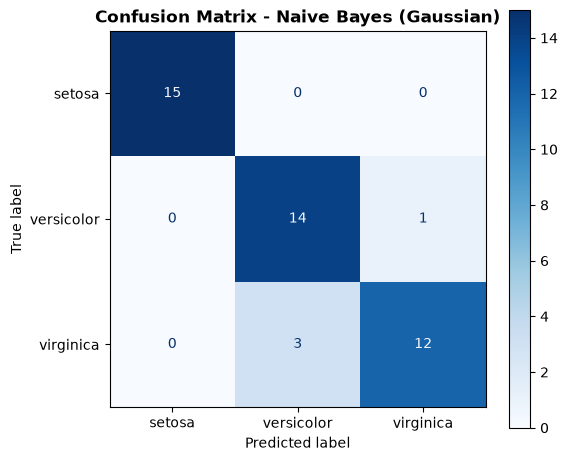

In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

iris = load_iris()
Xi = pd.DataFrame(iris.data, columns=iris.feature_names)
yi = iris.target

Xi_train, Xi_test, yi_train, yi_test = train_test_split(
    Xi, yi, test_size=0.3, random_state=42, stratify=yi)

nb = GaussianNB()
nb.fit(Xi_train, yi_train)
nb_pred = nb.predict(Xi_test)

print('Akurasi:', accuracy_score(yi_test, nb_pred))
print(classification_report(yi_test, nb_pred, target_names=iris.target_names, digits=3))

# --- Tambahan Confusion Matrix (Warna Biru) ---
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yi_test,
    nb_pred,
    display_labels=iris.target_names,
    cmap='Blues',
    ax=ax
)

plt.title('Confusion Matrix - Naive Bayes (Gaussian)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

Akurasi Euclidean (Default) : 0.9778
Akurasi Manhattan           : 0.9333
Apakah akurasi identik?     : False


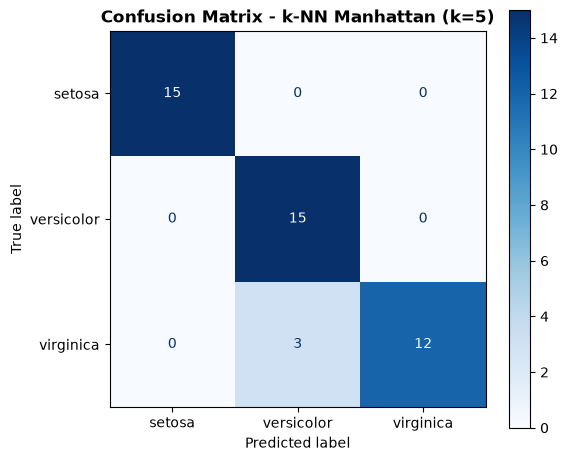

Akurasi Sebelum Scaling : 0.9778
Akurasi Sesudah Scaling : 0.9111
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        15
  versicolor      0.789     1.000     0.882        15
   virginica      1.000     0.733     0.846        15

    accuracy                          0.911        45
   macro avg      0.930     0.911     0.910        45
weighted avg      0.930     0.911     0.910        45



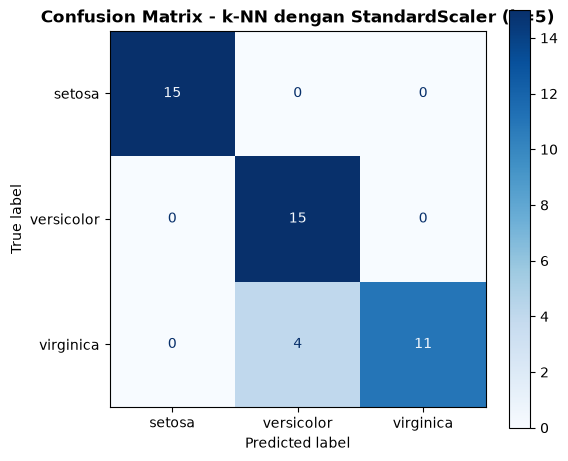

In [14]:
from sklearn.preprocessing import StandardScaler

# 1. k-NN Euclidean (Default)
knn_euc = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2) # p=2 ekuivalen Euclidean
knn_euc.fit(Xi_train, yi_train)
pred_euc = knn_euc.predict(Xi_test)
acc_euc = accuracy_score(yi_test, pred_euc)

# 2. k-NN Manhattan
knn_man = KNeighborsClassifier(n_neighbors=5, metric='manhattan')
knn_man.fit(Xi_train, yi_train)
pred_man = knn_man.predict(Xi_test)
acc_man = accuracy_score(yi_test, pred_man)

# 3. Perbandingan Akurasi
print(f'Akurasi Euclidean (Default) : {acc_euc:.4f}')
print(f'Akurasi Manhattan           : {acc_man:.4f}')
print(f'Apakah akurasi identik?     : {acc_euc == acc_man}')

# Visualisasi Confusion Matrix Manhattan
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yi_test, 
    pred_man, 
    display_labels=iris.target_names, 
    cmap='Blues', 
    ax=ax
)
plt.title('Confusion Matrix - k-NN Manhattan (k=5)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

# 1. Terapkan StandardScaler (fit hanya pada train, transform pada train & test)
scaler = StandardScaler()
Xi_train_scaled = scaler.fit_transform(Xi_train)
Xi_test_scaled = scaler.transform(Xi_test)

# 2. Latih model k-NN dengan data terstandardisasi
knn_scaled = KNeighborsClassifier(n_neighbors=5)
knn_scaled.fit(Xi_train_scaled, yi_train)
knn_scaled_pred = knn_scaled.predict(Xi_test_scaled)

# 3. Evaluasi dan perbandingan
acc_sebelum = accuracy_score(yi_test, knn_pred)
acc_sesudah = accuracy_score(yi_test, knn_scaled_pred)

print(f'Akurasi Sebelum Scaling : {acc_sebelum:.4f}')
print(f'Akurasi Sesudah Scaling : {acc_sesudah:.4f}')
print(classification_report(yi_test, knn_scaled_pred, target_names=iris.target_names, digits=3))

# Visualisasi Confusion Matrix Sesudah Scaling
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    yi_test, 
    knn_scaled_pred, 
    display_labels=iris.target_names, 
    cmap='Blues', 
    ax=ax
)
plt.title('Confusion Matrix - k-NN dengan StandardScaler (k=5)', fontsize=12, fontweight='bold')
plt.grid(False)
plt.tight_layout()
plt.show()

In [8]:
bunga_baru = pd.DataFrame([[5.0, 3.4, 1.5, 0.2]], columns=iris.feature_names)
pred_bunga = knn.predict(bunga_baru)
print('Prediksi kelas:', iris.target_names[pred_bunga[0]])


Prediksi kelas: setosa


k=1: akurasi = 0.9333
k=2: akurasi = 0.9111
k=3: akurasi = 0.9556
k=4: akurasi = 0.9556
k=5: akurasi = 0.9778
k=6: akurasi = 0.9556
k=7: akurasi = 0.9556
k=8: akurasi = 0.9333
k=9: akurasi = 0.9556
k=10: akurasi = 0.9556
k=11: akurasi = 0.9333
k=12: akurasi = 0.9333
k=13: akurasi = 0.9333
k=14: akurasi = 0.9333
k=15: akurasi = 0.9556
k=16: akurasi = 0.9556
k=17: akurasi = 0.9556
k=18: akurasi = 0.9556
k=19: akurasi = 0.9556
k=20: akurasi = 0.9333


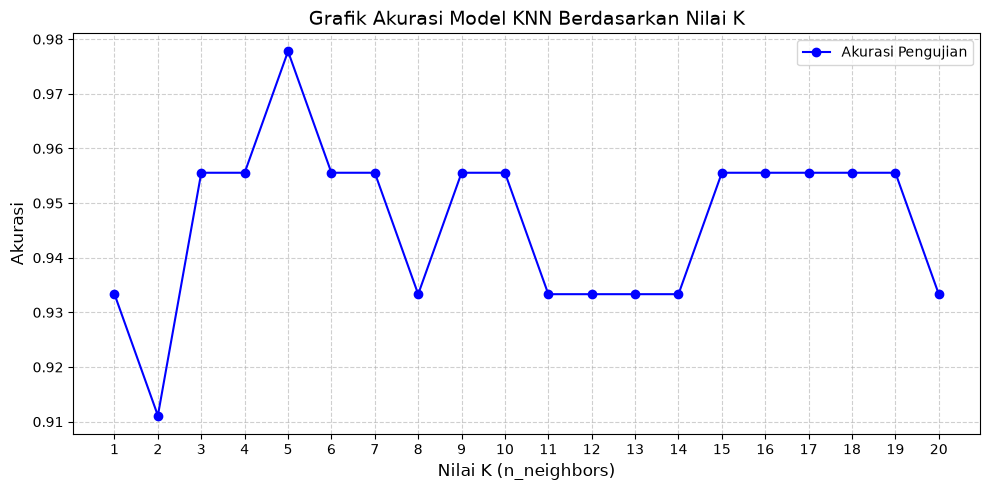

In [9]:
k_range = range(1, 21)
k_scores = []
for k in k_range:
 c = KNeighborsClassifier(n_neighbors=k)
 c.fit(Xi_train, yi_train)
 acc = accuracy_score(yi_test, c.predict(Xi_test))
 k_scores.append(acc)
 print(f'k={k}: akurasi = {acc:.4f}')

# 2. Buat diagram garis
plt.figure(figsize=(10, 5))
plt.plot(k_range, k_scores, color='blue', linestyle='-', marker='o', markersize=6, label='Akurasi Pengujian')

# Atribut grafik
plt.title('Grafik Akurasi Model KNN Berdasarkan Nilai K', fontsize=14)
plt.xlabel('Nilai K (n_neighbors)', fontsize=12)
plt.ylabel('Akurasi', fontsize=12)
plt.xticks(list(k_range))  # Memastikan semua angka k (1-20) tampil di sumbu X
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()


Naive Bayes (Gaussian): 0.9111111111111111
k-NN (k=5): 0.9777777777777777


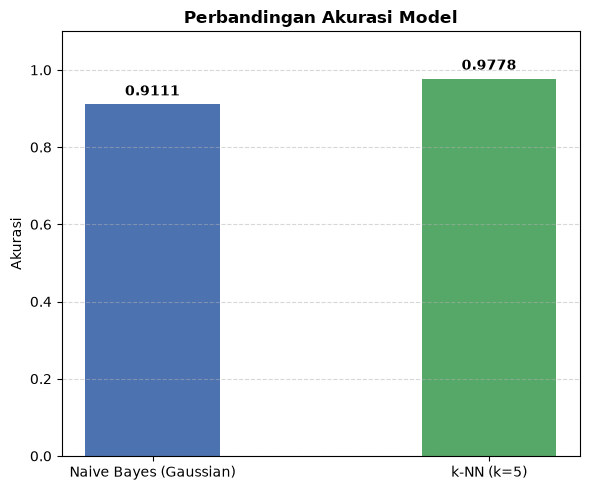

In [10]:
import matplotlib.pyplot as plt

nbg = accuracy_score(yi_test, nb_pred)
knnk5 = accuracy_score(yi_test, knn_pred)

print('Naive Bayes (Gaussian):', nbg)
print('k-NN (k=5):', knnk5)

# --- Tambahan kode barplot ---
model = ['Naive Bayes (Gaussian)', 'k-NN (k=5)']
skor = [nbg, knnk5]

fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(model, skor, color=['#4C72B0', '#55A868'], width=0.4)

# Menampilkan nilai skor di atas bar
ax.bar_label(bars, fmt='%.4f', padding=4, fontweight='bold')

# Pengaturan label dan batas sumbu
ax.set_title('Perbandingan Akurasi Model', fontsize=12, fontweight='bold')
ax.set_ylabel('Akurasi')
ax.set_ylim(0, 1.1)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()